In [ ]:
Step 1: Data Loading

In [1]:
import pandas as pd

df = pd.read_csv(r'C:\Capstone\local-dropshipping-ai-system\ai-engine\Sales_History.csv')
print(df.head())

   Order_Date  Product_Name     Category  Quantity  Cost_Price  Unit_Price  \
0  2025-04-26  Kain Pelikat     Clothing         7        12.0        25.0   
1  2025-04-26  Kain Pelikat     Clothing         6        12.0        25.0   
2  2025-04-26  Kain Pelikat     Clothing         1        12.0        25.0   
3  2025-04-26   Sampul Raya  Accessories         8         1.5         5.0   
4  2025-04-26  Kain Pelikat     Clothing         7        12.0        25.0   

   Total_Revenue Platform  
0          175.0   Shopee  
1          150.0   TikTok  
2           25.0   TikTok  
3           40.0   TikTok  
4          175.0   TikTok  


In [2]:
import matplotlib.pyplot as plt

# 2. Change date format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# 3. View data
print("Data is ready!")
df.head()


Data is ready!


,Order_Date,Product_Name,Category,Quantity,Cost_Price,Unit_Price,Total_Revenue,Platform
0,2025-04-26,Kain Pelikat,Clothing,7,12.0,25.0,175.0,Shopee
1,2025-04-26,Kain Pelikat,Clothing,6,12.0,25.0,150.0,TikTok
2,2025-04-26,Kain Pelikat,Clothing,1,12.0,25.0,25.0,TikTok
3,2025-04-26,Sampul Raya,Accessories,8,1.5,5.0,40.0,TikTok
4,2025-04-26,Kain Pelikat,Clothing,7,12.0,25.0,175.0,TikTok


In [3]:
import matplotlib.pyplot as plt

# 2. Change date format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# 3. View data
print("Data is ready!")
df.head()


Data is ready!


,Order_Date,Product_Name,Category,Quantity,Cost_Price,Unit_Price,Total_Revenue,Platform
0,2025-04-26,Kain Pelikat,Clothing,7,12.0,25.0,175.0,Shopee
1,2025-04-26,Kain Pelikat,Clothing,6,12.0,25.0,150.0,TikTok
2,2025-04-26,Kain Pelikat,Clothing,1,12.0,25.0,25.0,TikTok
3,2025-04-26,Sampul Raya,Accessories,8,1.5,5.0,40.0,TikTok
4,2025-04-26,Kain Pelikat,Clothing,7,12.0,25.0,175.0,TikTok


In [ ]:
Step 2: Visualization & Trends

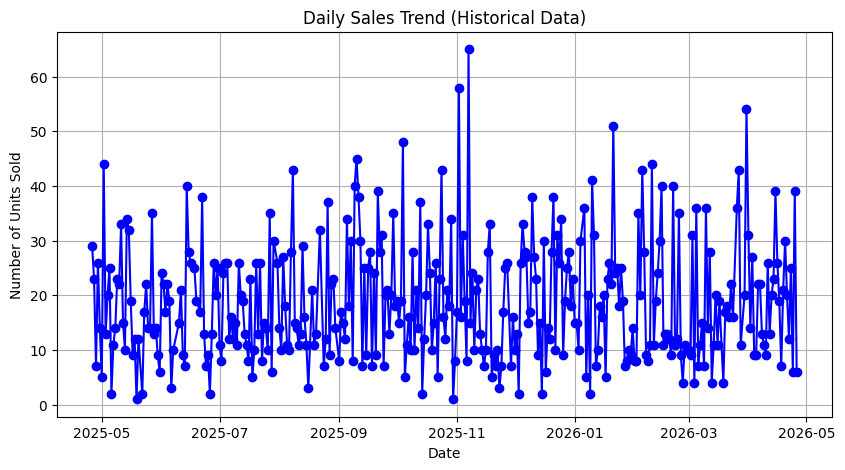

In [4]:
# 1. Collect sales by date (Total daily sales)
daily_sales = df.groupby('Order_Date')['Quantity'].sum().reset_index()

# 2. Plot graphs to see trends
plt.figure(figsize=(10, 5))
plt.plot(daily_sales['Order_Date'], daily_sales['Quantity'], marker='o', linestyle='-', color='b')
plt.title('Daily Sales Trend (Historical Data)')
plt.xlabel('Date')
plt.ylabel('Number of Units Sold')
plt.grid(True)
plt.show()

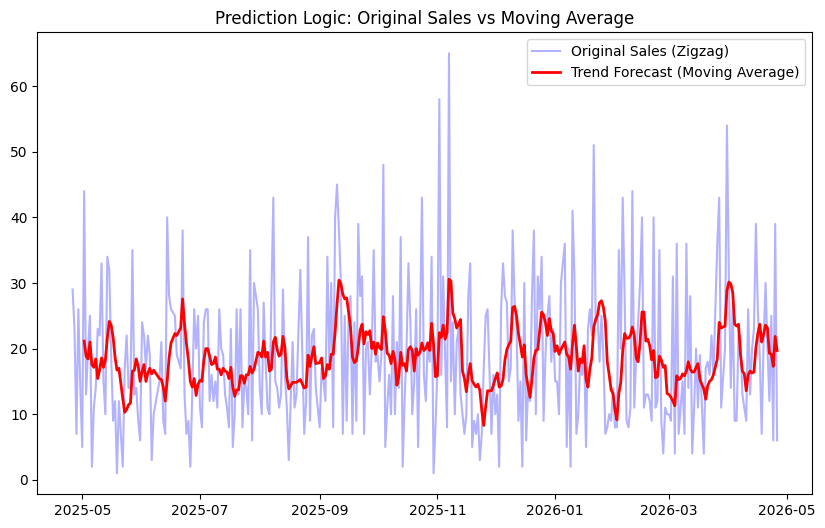

In [6]:
# 1.Calculate the moving average for 7 days (7-day Moving Average)
daily_sales['7day_MA'] = daily_sales['Quantity'].rolling(window=7).mean()

# 2. Plot the original graph vs. Average Prediction
plt.figure(figsize=(10, 6))
plt.plot(daily_sales['Order_Date'], daily_sales['Quantity'], label='Original Sales (Zigzag)', alpha=0.3, color='blue')
plt.plot(daily_sales['Order_Date'], daily_sales['7day_MA'], label='Trend Forecast (Moving Average)', color='red', linewidth=2)

plt.title('Prediction Logic: Original Sales vs Moving Average')
plt.legend()
plt.show()

In [ ]:
Step 3: Forecasting Logic

Average sales forecast for the next 30 days: 19.73 units per day


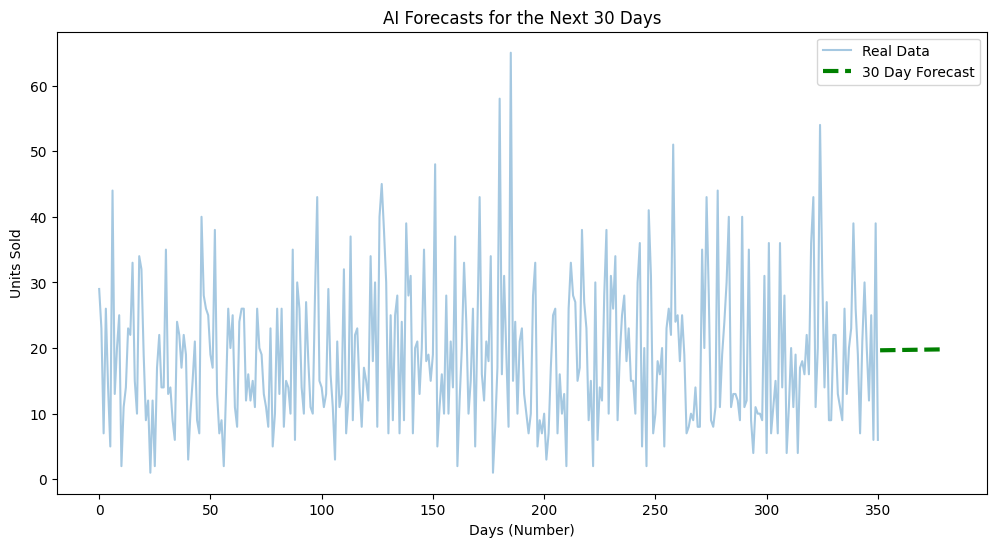

In [7]:
from sklearn.linear_model import LinearRegression
import numpy as np

# 1. Provide data for AI to learn (Convert dates to numbers)
daily_sales['Day_Num'] = np.arange(len(daily_sales))
X = daily_sales[['Day_Num']].values # Input: What day
y = daily_sales['Quantity']   # Output: How many units sold

# 2. Teach AI (Training)
model = LinearRegression()
model.fit(X, y)

# 3. Forecast 30 days ahead
future_days = np.arange(len(daily_sales), len(daily_sales) + 30).reshape(-1, 1)
future_predict = model.predict(future_days)

# 4. Show prediction results
print(f"Average sales forecast for the next 30 days: {future_predict.mean():.2f} units per day")

# 5. Plot the prediction graph
plt.figure(figsize=(12, 6))
plt.plot(daily_sales['Day_Num'], y, label='Real Data', alpha=0.4)
plt.plot(future_days, future_predict, label='30 Day Forecast', color='green', linestyle='--', linewidth=3)
plt.title('AI Forecasts for the Next 30 Days')
plt.xlabel('Days (Number)')
plt.ylabel('Units Sold')
plt.legend()
plt.show()

In [ ]:
Step 4: Top Seller Analysis (Sales Velocity)

In [11]:
product_velocity = (df.groupby('Product_Name')['Quantity'].sum() / df['Order_Date'].nunique()).round(2)
product_velocity = product_velocity.reset_index().rename(columns={'Quantity': 'Avg_Daily_Sales'})
print(product_velocity.sort_values(by='Avg_Daily_Sales', ascending=False))

        Product_Name  Avg_Daily_Sales
0  Baju Kurung Moden             2.97
1        Baju Melayu             2.84
2       Kain Pelikat             2.77
5       Tudung Bawal             2.66
4        Sampul Raya             2.58
6       Tudung Shawl             2.52
3     Kurta Slim Fit             2.44


In [ ]:
Step 5: Predictive Alerting

In [12]:
# 1.'Example Stock' (Because we don't have a data warehouse anymore)
inventory_data = {
    'Product_Name': [
        'Baju Kurung Moden', 'Baju Melayu', 'Kain Pelikat', 
        'Tudung Bawal', 'Sampul Raya', 'Tudung Shawl', 'Kurta Slim Fit'
    ],
    'Current_Stock': [50, 40, 15, 10, 100, 25, 5] 
}

inventory_df = pd.DataFrame(inventory_data)

# 2. COMBINE the sample stock data with the sales data from the dataset
alert_system = pd.merge(product_velocity, inventory_df, on='Product_Name')

# 3. LOGICAL CALCULATION: Days_Remaining = Current_Stock / Avg_Daily_Sales
alert_system['Days_Until_Stockout'] = alert_system['Current_Stock'] / alert_system['Avg_Daily_Sales']
alert_system = alert_system.round(2)

# 4. DISPLAY RESULTS (Predictive Alerting)
print("--- STOCK WARNING SYSTEM (PREDICTIVE ALERTING) ---")
print(alert_system[['Product_Name', 'Avg_Daily_Sales', 'Current_Stock', 'Days_Until_Stockout']])

--- STOCK WARNING SYSTEM (PREDICTIVE ALERTING) ---
        Product_Name  Avg_Daily_Sales  Current_Stock  Days_Until_Stockout
0  Baju Kurung Moden             2.97             50                16.84
1        Baju Melayu             2.84             40                14.08
2       Kain Pelikat             2.77             15                 5.42
3     Kurta Slim Fit             2.44              5                 2.05
4        Sampul Raya             2.58            100                38.76
5       Tudung Bawal             2.66             10                 3.76
6       Tudung Shawl             2.52             25                 9.92
